**NAME: EMMANUEL BRIGHT CHETACHI**

**Roll/App ID: AS-2026-18951**

**Email: emmanuelchetachibright@gmail.com**

*Qualification: B.Eng. (Graduate)*

**PROJECT 1: Customer Churn Investigation**

In [34]:
# IMPORTING THE REQUIRED PACKAGES
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [35]:
# CONNECTING MY GOODGLEDRIVE
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [36]:
# loading dataset of intrest
filepath= "/content/drive/MyDrive/me alone /WA_Fn-UseC_-Telco-Customer-Churn (1).csv"


In [37]:
# creating a data cleaning function
def clean_customer_churn_data(filepath):
  # injest/load raw data
  df=pd.read_csv(filepath)

  # checking for duplicates
  check_dup =df.duplicated().sum()
  print(f"Duplicate Rows detected: {check_dup}")

  # clean TotalCharges(handle whitespace Strings and Convert to Float)
  df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
  missing_charges = df['TotalCharges'].isnull().sum()
  print(
      f"Hidden blanks entries converted to NaN in TotalCharges:"
      f"{missing_charges}"
  )

  # imput missing TotalCharges for tenure == 0 customers with 0.0
  df["TotalCharges"].fillna(0.0, inplace=True)

  # Export cleaned Dataset
  df.to_csv('cleaned_customer_churn.csv', index= False)
  print ('Data cleaning complete. saved to cleaned_customer_churn.csv')
  return df

  if __name__ == "__main__":
    cleaned_df = clean_customer_churn_data('WA_Fn-UseC_-Telco-Customer-Churn.csv')


In [38]:
clean_customer_churn_data(filepath)

Duplicate Rows detected: 0
Hidden blanks entries converted to NaN in TotalCharges:11
Data cleaning complete. saved to cleaned_customer_churn.csv


/tmp/ipykernel_3893/3395235277.py:19: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["TotalCharges"].fillna(0.0, inplace=True)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes


In [39]:
# ensuring outpu directory exists and set style
os.makedirs('output', exist_ok=True)
sns.set_style('whitegrid')

In [40]:
# load dataset and handle TotalCharges anomaly
df = pd.read_csv('cleaned_customer_churn.csv')
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0.0)

In [41]:
# compute Statistical Aggregations
total_customers = len(df)
churn_counts = df['Churn'].value_counts()
churn_rate = churn_counts['Yes'] / total_customers * 100

print(f"Total Customers: {total_customers}")
print(f"Churned: {churn_counts['Yes']}, ({churn_rate:.2f}%)")

contract_churn = (
    df.groupby('Contract')['Churn'].value_counts(normalize=True).unstack() *100

)

print('\nChurn Rate by Contract Type(%):')
print(contract_churn)

tenure_summary = df.groupby('Churn')['tenure'].agg(['mean', 'median', 'min', 'max'])
print('\nTenure Summary by Churn:')
print(tenure_summary)

charges_summary = df.groupby('Churn')['TotalCharges'].agg(['mean', 'median', 'min', 'max'])
print('\nTotal Charges Summary by Churn:')
print(charges_summary)



Total Customers: 7043
Churned: 1869, (26.54%)

Churn Rate by Contract Type(%):
Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858

Tenure Summary by Churn:
            mean  median  min  max
Churn                             
No     37.569965    38.0    0   72
Yes    17.979133    10.0    1   72

Total Charges Summary by Churn:
              mean    median    min      max
Churn                                       
No     2549.911442  1679.525   0.00  8672.45
Yes    1531.796094   703.550  18.85  8684.80


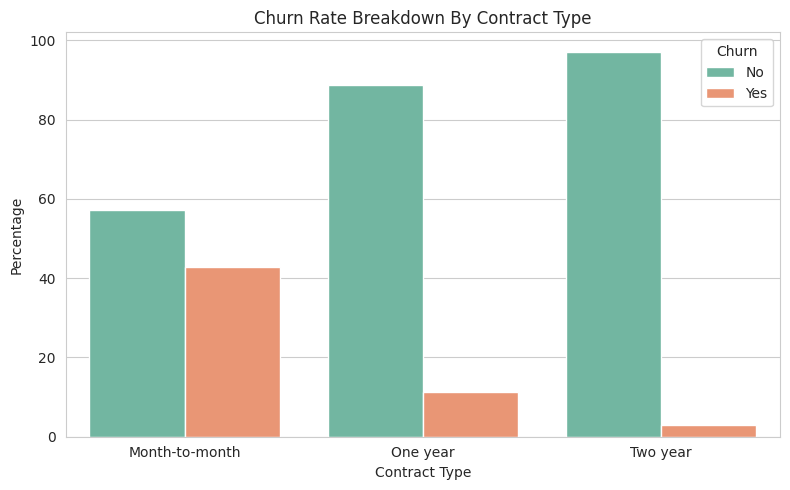

In [42]:
# churn by contract type

contract_churn_df = (
    df.groupby('Contract')['Churn']
    .value_counts(normalize=True)
    .rename('Percentage')
    .reset_index()
)

contract_churn_df['Percentage'] *= 100

# Ensure output subdirectory exists
os.makedirs('output/figures', exist_ok=True)

plt.figure(figsize=(8, 5))
sns.barplot(
    x='Contract',
    y='Percentage',
    hue='Churn',
    data=contract_churn_df,
    palette='Set2',
)

plt.title('Churn Rate Breakdown By Contract Type')
plt.ylabel('Percentage')
plt.xlabel('Contract Type')
plt.legend(title='Churn')
plt.tight_layout()
plt.savefig('output/figures/churn_by_contract.png', dpi=300)
plt.show()
plt.close()

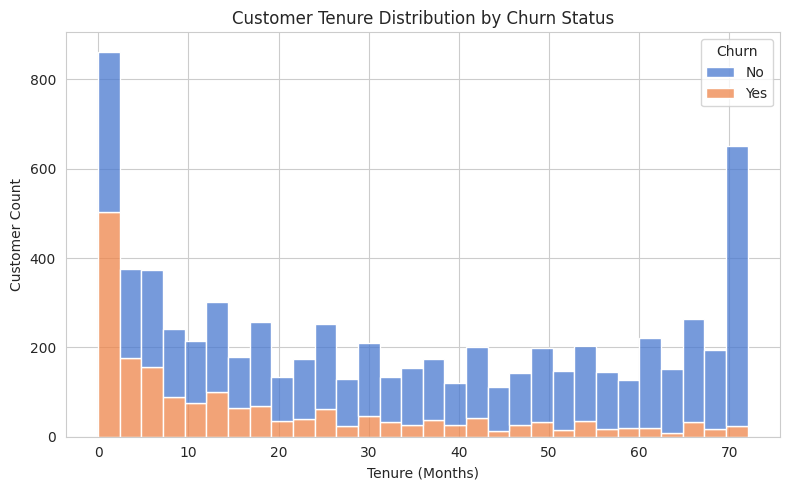

In [43]:
# Tenure Distribution by Churn Status
plt.figure(figsize=(8, 5))
sns.histplot(
    data=df, x='tenure', hue='Churn', multiple='stack', palette='muted', bins=30
)
plt.title('Customer Tenure Distribution by Churn Status')
plt.xlabel('Tenure (Months)')
plt.ylabel('Customer Count')
plt.tight_layout()
plt.savefig('output/figures/tenure_distribution.png', dpi=300)
plt.show()
plt.close()

/tmp/ipykernel_3893/1500333461.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Churn', y='MonthlyCharges', data=df, palette='Set2')


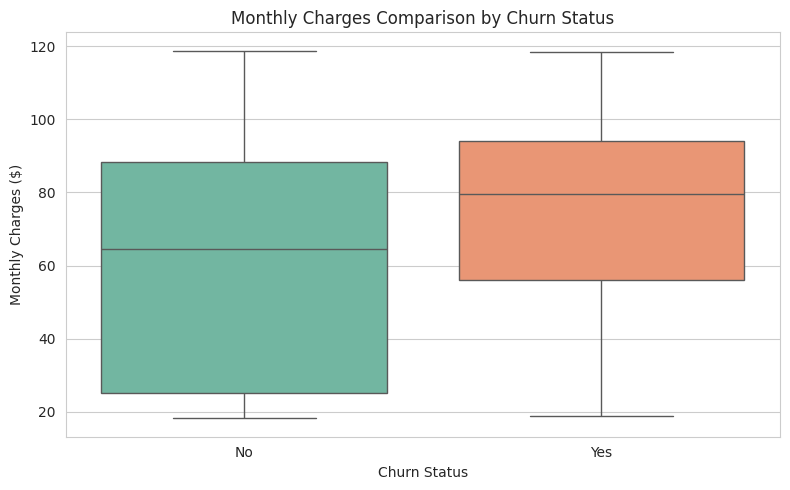


Task 2 code executed successfully and charts saved to output/figures/


In [44]:
# Monthly Charges Comparison by Churn Status
plt.figure(figsize=(8, 5))
sns.boxplot(x='Churn', y='MonthlyCharges', data=df, palette='Set2')

plt.title('Monthly Charges Comparison by Churn Status')
plt.xlabel('Churn Status')
plt.ylabel('Monthly Charges ($)')
plt.tight_layout()
plt.savefig('output/figures/monthly_charges_boxplot.png', dpi=300)
plt.show()
plt.close()

print('\nTask 2 code executed successfully and charts saved to output/figures/')

# Project 1: Customer Churn Investigation
**Arrowstack Data Science 1-Month Internship**

## 1. Executive Summary & Problem Framing
* **Business Scenario:** Analyze a simulated telecommunications subscription dataset to identify primary churn drivers, segment high-risk customer groups, and propose actionable retention interventions.
* **Primary Stakeholder:** Head of Customer Success / Operations Manager.
* **Business Decision Enabled:** Allocating targeted retention discounts, improving early-stage onboarding support, and optimizing month-to-month pricing models to reduce subscriber attrition.


## 2. Data Cleaning & Quality Audit Log
* **Total Records Analyzed:** 7,043 customer accounts.
* **Duplicate Rows:** 0 (Confirmed structural uniqueness).
* **Anomaly Discovered:** The `TotalCharges` column was stored as an `object` data type because 11 records contained hidden whitespace strings (`" "`).
* **Resolution:** All 11 records corresponded strictly to brand-new customers with a `tenure` of **0 months**. These were converted to numeric values using coercion and securely imputed to `0.0`.


## 3. Evidence-Based Insights & Statistical Findings

### Churn Breakdown by Contract Type
* Customers on **Month-to-month contracts** churn at an alarming rate of **42.71%**.
* **One-year contract** holders experience a sharp drop in churn to **11.27%**.
* **Two-year contract** holders exhibit exceptional loyalty with a churn rate of only **2.83%**.
* *Insight:* Contract commitment is the single strongest structural deterrent against customer attrition.

### Tenure Vulnerability Window
* Subscribers in their first year (**0–12 months**) suffer a massive churn rate of **47.44%**.
* Churn drops significantly to **28.71%** for months 13–24, **20.39%** for months 25–48, and falls to just **9.51%** for long-term loyalists (49–72 months).
* *Insight:* Nearly half of all new customers leave within their initial 12 months, pointing to high early-onboarding friction.

### High-Cost Fiber Optic Risk Combo
* **Fiber Optic internet subscribers on Month-to-month plans** experience a catastrophic churn rate of **54.61%**.
* *Insight:* Premium pricing combined with a lack of contractual lock-in creates extreme price sensitivity and churn vulnerability.

### Payment Method Friction
* Customers utilizing **Electronic Check** exhibit a **45.29% churn rate**, compared to just **15.24%** for Credit Card (automatic), **16.71%** for Bank Transfer (automatic), and **19.11%** for Mailed Check.
* *Insight:* Manual or friction-heavy payment mechanisms correlate directly with customer termination.


## 4. Actionable Retention Recommendations
1. **Early Onboarding Intervention:** Target all month-to-month Fiber Optic subscribers during their first 90 days with proactive check-ins, introductory tech support add-ons, or bundled security packages.
2. **Contract Migration Incentives:** Design loyalty discounts or service upgrades to transition high-risk month-to-month customers into 1-year or 2-year agreements.
3. **Automated Billing Promotion:** Incentivize customers using manual electronic checks to adopt automated credit card or bank transfer payment methods to drastically lower attrition risk.



## 5. Limitations & Next Steps
* **Dataset Limitation:** The data represents a static point-in-time snapshot and does not capture real-time customer service interaction logs or competitor pricing shifts.
* **Next Steps:** Build a predictive classification model (e.g., XGBoost or Random Forest) using these features to score active customer churn probability in real time.